# 01. Ray fundamentals and offline inference at scale

**AI Drug Discovery & Development Summit 2026 · Hands-on workshop · Part 1 of 3**

**Workshop series:** [01 Ray and offline inference](01_ray_and_offline_inference.ipynb) · [02 Train and tune](02_train_and_tune.ipynb) · [03 Serve](03_serve.ipynb)

Co-folding models such as Boltz-2 and OpenFold3 predict how a small molecule binds its protein target
from the protein sequence and the molecule's chemical structure alone. Their published accuracy is
measured on curated benchmarks. This workshop examines 2 questions about real drug discovery campaigns:

1. **How well do these models generalize** to a new target and to compounds designed months into a campaign?
2. **Can a small amount of target-specific data close the gap**, and at what cost?

Both are measured on **2,147 X-ray crystal structures** from 3 antiviral campaigns, using a workflow built
end to end on Ray.

![The workshop end to end](docs/images/workshop.gif)

This notebook covers Ray Core and offline batch inference with Ray Data: the cluster, tasks, actors and
objects, then prediction and scoring across 3 campaigns.

| § | Topic | Ray library | Min |
|---|---|---|---|
| 0 | Setup | | 3 |
| 1 | Ray fundamentals | Ray Core | 12 |
| 2 | The data: 3 drug discovery campaigns | | 5 |
| 3 | Prediction and scoring at scale | Ray Data | 20 |
| 4 | Results across 3 campaigns | | 8 |

Fine-tuning (Ray Train and Ray Tune) is notebook 02; serving (Ray Serve) is notebook 03.

**Running this notebook**

- Run the cells in order with **Shift+Enter**. Cells marked ⏱ take several minutes while GPU nodes start.
- The presenter runs every GPU step live on a shared L4 cluster. Attendees keep `USE_GPUS = False`:
  the same cells then load stored results.
- Scientific background (pose scoring, campaign structure) is in the [README](README.md#background).


## 0. Setup

- The Workspace runs the `aiddd-boltz2-of3` image: Ray, Boltz-2 and 2 OpenFold3 versions (0.5 and 0.4.3).
- This notebook runs on a CPU-only head node. L4 GPU nodes join when a cell requests a GPU and leave when idle.
- Data, model weights and all benchmark results live on shared storage.

In [34]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import ray

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)

from aiddd_pipeline import (SHARED, TARGETS, BOLTZ_CACHE, OF3_OB_CKPT, OF3_P2_CKPT, OF3_FT_CKPT, OF3_LEGACY,
                            Boltz2Predictor, OF3Predictor, load_ligands, validate, make_scorer)
import workshop_helpers as wh

# Data and weights are downloaded once, ahead of the workshop (README step 2)
needed = [TARGETS[t].path("metadata") for t in wh.TARGET_KEYS] + [BOLTZ_CACHE, OF3_OB_CKPT, OF3_P2_CKPT, OF3_FT_CKPT]
missing = [str(p) for p in needed if not p.exists()]
assert not missing, f"Missing {missing}. Run `python scripts/setup_data.py` and `python scripts/prepare_mpro.py` first."

# True: run every GPU step live (the presenter, or anyone with their own GPUs).
# False: GPU steps load stored results. Serving is notebook 03.
USE_GPUS = False
SERVICE_URL = os.environ.get("AIDDD_SERVICE_URL", "")   # the deployed prediction service used in notebook 03
GPU = "L4"            # GPU type for every GPU step in this notebook

wh.MINE.mkdir(parents=True, exist_ok=True)
print(f"shared data:  {SHARED}")
print(f"your outputs: {wh.MINE}")

try:
    ray.init(runtime_env={"env_vars": {"AIDDD_SHARED": str(SHARED)}}, ignore_reinit_error=True, logging_level="ERROR")
except ValueError:   # inside an Anyscale Job, which already sets the environment
    ray.init(ignore_reinit_error=True, logging_level="ERROR")
dashboard = os.environ.get("RAY_OVERRIDE_DASHBOARD_URL") or ray.get_runtime_context().dashboard_url
print(f"Ray Dashboard metrics: {dashboard.rstrip('/')}/#/metrics   (open in a new browser tab)")

shared data:  /mnt/user_storage/aiddd
your outputs: /mnt/user_storage/aiddd/workshop/alicia_chua_30e1ffa
Ray Dashboard metrics: https://session-thqdxs9cduqis7hsp7r4mvd42v.i.anyscaleuserdata.com/#/metrics   (open in a new browser tab)


## 1. Ray fundamentals

A single Boltz-2 prediction takes about 1 minute on 1 GPU. The full benchmark (2,147 structures, 4 models,
3 proteins) is several days of work for a single GPU, before any fine-tuning or serving.

Ray runs Python across a cluster. **Ray Core** provides 3 primitives (tasks, actors and objects), and the
Ray AI libraries for data, training, tuning and serving are built on them. This workshop uses all 4 libraries.

<img src="docs/images/ray/map-of-ray.svg" alt="Ray overview" width="460">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

### 1.1 The cluster

- A **head node** runs this notebook (the *driver*) and the **autoscaler**.
- **Worker nodes** join when pending work needs resources and leave when idle.
- Every node runs a scheduler and an **object store**: shared memory that holds results, so other processes
  read them without copying.
- This Workspace has 2 worker types: CPU nodes for cheminformatics and scoring, L4 GPU nodes for inference.

<img src="docs/images/ray/ray-cluster.svg" alt="Ray cluster" width="620">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

In [67]:
def cluster_table():
    rows = []
    for n in ray.nodes():
        if not n["Alive"]:
            continue
        r = n["Resources"]
        rows.append({"node": n["NodeManagerHostname"], "head": "node:__internal_head__" in r,
                     "CPUs": int(r.get("CPU", 0)), "GPUs": int(r.get("GPU", 0)),
                     "GPU type": next((k.split(":")[1] for k in r if k.startswith("accelerator_type:")), ""),
                     "memory (GB)": round(r.get("memory", 0) / 1e9)})
    return pd.DataFrame(rows).sort_values(["head", "GPUs"], ascending=False).reset_index(drop=True)

cluster_table()   # run again later to watch nodes join and leave

,node,head,CPUs,GPUs,GPU type,memory (GB)
0,ip-10-0-145-218,True,0,0,,34
1,ip-10-0-186-239,False,8,1,L4,34
2,ip-10-0-161-156,False,8,1,L4,34
3,ip-10-0-185-138,False,8,1,L4,34
4,ip-10-0-116-101,False,8,1,L4,34
5,ip-10-0-216-201,False,8,1,L4,34
6,ip-10-0-148-167,False,8,1,L4,34
7,ip-10-0-248-133,False,8,1,L4,34
8,ip-10-0-212-151,False,8,1,L4,34
9,ip-10-0-132-66,False,8,1,L4,34


### 1.2 Tasks

- `@ray.remote` turns a function into a **task**.
- `.remote()` schedules it on any node with a free CPU and immediately returns an **`ObjectRef`**.
- `ray.get` waits for the result.

Below: 16 steps of 1 second each, first in plain Python, then as 16 Ray tasks. The first run may include
node startup; run the cell again to time the tasks alone.

In [68]:
def slow_step(i):
    time.sleep(1)          # stands in for 1 second of work, such as featurizing a molecule
    return i * i

t0 = time.time()
serial = [slow_step(i) for i in range(16)]
print(f"plain Python: {time.time() - t0:4.1f} s")

slow_task = ray.remote(slow_step)            # the same function as a Ray task
t0 = time.time()
refs = [slow_task.remote(i) for i in range(16)]
print(f"16 tasks submitted in {time.time() - t0:.3f} s, first reference: {refs[0]}")
parallel = ray.get(refs)
print(f"Ray tasks:    {time.time() - t0:4.1f} s, identical results: {parallel == serial}")

plain Python: 16.0 s
16 tasks submitted in 0.005 s, first reference: ObjectRef(aa1b5f1ad0fb9456ffffffffffffffffffffffff0300000001000000)
Ray tasks:     1.2 s, identical results: True


A realistic version: RDKit descriptors for every compound in the 3 campaigns, in 16 chunks across the
cluster. Each chunk records the node it ran on.

In [37]:
@ray.remote(num_cpus=1)
def describe(smiles: list[str]) -> pd.DataFrame:
    # Molecular weight, ring count and hydrogen-bond donors for each SMILES string
    import socket
    from rdkit import Chem
    from rdkit.Chem import Descriptors, Lipinski
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        rows.append({"smiles": s, "mol_weight": Descriptors.MolWt(m) if m else None,
                     "rings": Lipinski.RingCount(m) if m else None,
                     "hbond_donors": Lipinski.NumHDonors(m) if m else None, "node": socket.gethostname()})
    return pd.DataFrame(rows)

smiles = pd.concat([pd.read_csv(TARGETS[t].path("metadata")).smiles.drop_duplicates() for t in wh.TARGET_KEYS])
chunks = np.array_split(smiles.to_numpy(), 16)

t0 = time.time()
props = pd.concat(ray.get([describe.remote(list(c)) for c in chunks]))
print(f"{len(props)} molecules, 16 tasks, {time.time() - t0:.1f} s, {props.node.nunique()} node(s)")
props.drop(columns="node").describe().round(1)

1285 molecules, 16 tasks, 0.5 s, 5 node(s)


,mol_weight,rings,hbond_donors
count,1285.0,1285.0,1285.0
mean,375.7,3.6,1.1
std,122.5,1.7,0.7
min,73.1,0.0,0.0
25%,286.3,2.0,1.0
50%,352.2,3.0,1.0
75%,483.5,5.0,1.0
max,848.4,8.0,4.0


### 1.3 Resources and GPUs

- Each task or actor declares what it needs: `num_cpus`, `num_gpus`, and optionally a GPU model via `accelerator_type`.
- Ray places it where those resources are free; if none are, the autoscaler starts a node.
- GPU requests can be fractional: `num_gpus=0.5` puts 2 processes on 1 GPU. Section 3 uses this so 1 predictor
  computes while the other prepares its next molecule on the CPU.

The next cell requests 2 tasks of half an L4 each and moves on without waiting. If no L4 node is running,
the autoscaler starts a node now, so it is ready for Section 3. With `USE_GPUS = False` the request is skipped.

In [38]:
@ray.remote(num_gpus=0.5)
def which_gpu(name):
    import socket, subprocess
    gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True).stdout.strip()
    return {"task": name, "node": socket.gethostname(), "GPU ids assigned by Ray": ray.get_gpu_ids(), "GPU": gpu}

gpu_refs = []
if USE_GPUS:
    gpu_refs = [which_gpu.options(accelerator_type=GPU).remote(n) for n in ("predictor A", "predictor B")]   # returns immediately
    print(f"Requested 2 x 0.5 {GPU}. GPUs free right now: {ray.available_resources().get('GPU', 0)}")
else:
    print("USE_GPUS is False: the GPU request runs on the presenter's cluster.")

USE_GPUS is False: the GPU request runs on the presenter's cluster.


### 1.4 Objects

Task inputs and outputs live in the object store. A large input shared by many tasks (a metadata table,
fingerprints, model weights) is stored once with `ray.put`; every task receives the same `ObjectRef` and
reads the copy on its own node.

<img src="docs/images/ray/objects.png" alt="Objects in Ray" width="300">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

In [39]:
meta_all = pd.concat([pd.read_csv(TARGETS[t].path("metadata")).assign(target=t) for t in wh.TARGET_KEYS])
meta_ref = ray.put(meta_all)                     # stored once in the object store
print(f"metadata: {len(meta_all)} rows, stored as {meta_ref}")

@ray.remote
def count_phase(meta: pd.DataFrame, target: str) -> dict:
    # Ray passes the table itself to the task, resolved from the ObjectRef
    m = meta[meta.target == target]
    return {"target": TARGETS[target].name, "fragment-screen structures": int(m.fragment_screen.sum()),
            "follow-on structures": int((~m.fragment_screen.astype(bool)).sum())}

pd.DataFrame(ray.get([count_phase.remote(meta_ref, t) for t in wh.TARGET_KEYS]))

metadata: 2147 rows, stored as ObjectRef(00ffffffffffffffffffffffffffffffffffffff0300000004e1f505)


,target,fragment-screen structures,follow-on structures
0,EV-A71 2A protease,113,812
1,SARS-CoV-2 Mpro,59,569
2,MERS-CoV Mpro,0,594


### 1.5 Task graphs and `ray.wait`

- An `ObjectRef` can be passed straight into another task: Ray starts it once the input is ready, so a whole
  graph of work is submitted at once.
- `ray.wait` returns results as they complete, which is useful for progress reporting.

In [40]:
@ray.remote
def heaviest(df: pd.DataFrame) -> pd.Series:
    return df.sort_values("mol_weight").iloc[-1]

# describe, then heaviest, submitted together; no ray.get in between
chained = [heaviest.remote(describe.remote(list(c))) for c in chunks[:6]]

pending, finished = chained, 0
while pending:
    ready, pending = ray.wait(pending, num_returns=1)
    finished += 1
    top = ray.get(ready[0])
    print(f"{finished}/6 finished: heaviest molecule {top.mol_weight:6.1f} Da  {top.smiles[:50]}")

1/6 finished: heaviest molecule  249.3 Da  Cc1ccc(OCC(=O)N2CCOCC2)c(C)c1
2/6 finished: heaviest molecule  412.9 Da  Cc1nn(C)c(C)c1CC(=O)N[C@@H](CNC(=O)CCl)c1ccc2ccccc
3/6 finished: heaviest molecule  403.3 Da  CS(=O)(=O)c1ccc(Br)cc1CC(=O)N1CCC[C@H](C(N)=O)C1
4/6 finished: heaviest molecule  415.4 Da  COC[C@]1(C)C[C@H](C(N)=O)CN1C(=O)Cc1cc(Br)ccc1SC
5/6 finished: heaviest molecule  385.3 Da  COc1cc(Br)c(CC(=O)N2CCC[C@H](C(N)=O)C2)cc1OC
6/6 finished: heaviest molecule  393.9 Da  COc1cccc(Cl)c1CC(=O)N1C[C@H](C(N)=O)C[C@H](C(=O)NC


### 1.6 Actors

An **actor** is a class decorated with `@ray.remote`. Ray creates it once on 1 node; it keeps its state
between calls. Actors are the natural home for anything expensive to load, such as a co-folding model with
several GB of weights on a GPU. All predictors in Section 3 are actors.

The actor below loads the EV-A71 2A fragment screen once, then reports how similar any new compound is to
its nearest fragment.

In [41]:
@ray.remote(num_cpus=1)
class FragmentMemory:
    def __init__(self, fragment_smiles):
        from rdkit import Chem, DataStructs
        from rdkit.Chem import rdFingerprintGenerator
        self.gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
        self.DS, self.Chem = DataStructs, Chem
        self.fps = [self.gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in fragment_smiles]   # loaded once
        self.queries = 0

    def nearest(self, smiles):
        self.queries += 1                                                                      # kept between calls
        fp = self.gen.GetFingerprint(self.Chem.MolFromSmiles(smiles))
        return max(self.DS.BulkTanimotoSimilarity(fp, self.fps))

    def stats(self):
        return f"{len(self.fps)} fragments loaded, {self.queries} queries answered"

meta_ev71 = meta_all[meta_all.target == "ev71-2a"]
memory = FragmentMemory.remote(meta_ev71[meta_ev71.fragment_screen].smiles.unique().tolist())

late = meta_ev71[~meta_ev71.fragment_screen].drop_duplicates("compound_group").tail(5)
sims = ray.get([memory.nearest.remote(s) for s in late.smiles])
print(ray.get(memory.stats.remote()))
pd.DataFrame({"compound": late.compound_group, "similarity to closest fragment (0 to 1)": np.round(sims, 2)})

83 fragments loaded, 5 queries answered


,compound,similarity to closest fragment (0 to 1)
920,x7597a,0.40
921,x7608a,0.20
922,x7613a,0.27
923,x7622a,0.21
924,x7631a,0.25


Many follow-on compounds have a similarity well below 0.5 to every fragment: they contain chemistry the
fragment screen never sampled. That makes them the harder and more relevant test, and every result in this
notebook is reported separately for fragments and follow-ons.

### 1.7 Fault tolerance

On a large cluster, failures are routine: a spot instance is reclaimed, a node runs out of memory, an
external tool fails on 1 input.

- Tasks retry automatically (`max_retries`; `retry_exceptions=True` includes Python exceptions).
- Actors restart (`max_restarts`).
- Ray Train restarts a whole training run from its last checkpoint (notebook 02, Section 5.5).

Below, each attempt fails with 30% probability, yet all 20 tasks complete. The retry messages above the
result are expected.

In [42]:
@ray.remote(max_retries=10, retry_exceptions=True)
def unreliable_step(i):
    import random
    if random.random() < 0.3:
        raise RuntimeError("simulated node failure")
    return i

print(f"{len(ray.get([unreliable_step.remote(i) for i in range(20)]))} of 20 tasks completed")

(raylet) Task unreliable_step failed. There are 10 retries remaining, so the task will be retried. Error: User exception:
ray::unreliable_step() (pid=4881, ip=10.0.216.201)
  File "/tmp/ipykernel_38243/3500811816.py", line 5, in unreliable_step
RuntimeError: simulated node failure
20 of 20 tasks completed


### 1.8 GPU placement and the 4 Ray libraries

The 2 GPU tasks from Section 1.3 have had time to start. The cell waits up to 1 minute for them.

In [43]:
if not gpu_refs:
    print("Skipped: USE_GPUS is False.")
else:
    ready, pending = ray.wait(gpu_refs, num_returns=len(gpu_refs), timeout=60)
    if pending:
        print(f"The GPU node is still starting. Run this cell again in a few minutes. {cluster_table().GPUs.sum()} GPUs up.")
    else:
        display(pd.DataFrame(ray.get(ready)))

Skipped: USE_GPUS is False.


Each task received half an L4; `ray.get_gpu_ids()` reports which device. The rest of the workshop builds
on these primitives:

| Library | Built on | In this workshop |
|---|---|---|
| **Ray Data** | Tasks for CPU stages, actor pools for model stages, streaming through the object store | Prediction with 4 models and scoring against crystal structures |
| **Ray Train** | 1 actor per GPU in a PyTorch DDP group, with checkpoints and automatic restarts | Fine-tuning OpenFold3 on 8 GPUs |
| **Ray Serve** | Actor replicas behind an HTTP proxy, with autoscaling | The 3D results viewer and live prediction |
| **Ray Tune** | 1 trial per configuration, with early-stopping schedulers | Learning-rate and inference sweeps (Appendix) |

![Workflow](docs/images/workflow.png)

Keep the **Metrics** page of the Ray Dashboard open in a separate tab (link printed in Setup).

| Panel | Healthy | Needs attention |
|---|---|---|
| **Node GPU** | Near 100% while a model predicts | Long stretches near 0%: GPUs wait on CPU stages or model loading |
| **Node GPU Memory** | Stable, below the 24 GB of an L4 | Near the limit: lower `batch_size` or give each actor a full GPU |
| **Node Count** | GPU nodes join within minutes | No change: no capacity available |
| **Scheduler Task / Actor State** | Pending → running → finished | Many tasks pending for minutes: resources missing |
| **Object Store Memory** | Rises and falls with each batch | Grows without falling, or spills to disk |
| **Ray Data: Rows output / second** | Every operator produces rows | 1 operator at 0 while others wait: the bottleneck |

> Watch 3 panels: **GPU utilization** (are GPUs busy?), **Node Count** (have nodes started?) and
> **Scheduler Task State** (is anything stalled?).

## 2. The data: 3 drug discovery campaigns

A campaign has 2 phases:

- **Fragment screen.** Hundreds of small molecules (~15 heavy atoms) are soaked into protein crystals; each
  hit is solved as a crystal structure. Structures are cheap and plentiful here.
- **Follow-on design.** Chemists grow the best fragments into larger, tighter binders over months. Only a
  fraction is ever crystallized. **Reliable predicted poses are most valuable at this stage, and least
  reliable in practice.**

All 3 targets are viral proteases. The crystal structures are ground truth; the models see only the
protein sequence and each compound's SMILES string.

![From fragment screen to optimized compound](docs/images/campaign_explained.gif)

In [44]:
rows, ligands = [], {}
for t in wh.TARGET_KEYS:
    meta, lig = load_ligands(TARGETS[t])
    ligands[t] = lig
    rows.append({"target": TARGETS[t].name,
                 "crystal structures": len(meta),
                 "unique compounds": len(lig),
                 **{st: int((lig.stage == st).sum()) for st in ["fragment", "early follow-on", "late follow-on"]},
                 "with measured affinity": int(lig.experimental_pKD.notna().sum())})
pd.DataFrame(rows).set_index("target")

,crystal structures,unique compounds,fragment,early follow-on,late follow-on,with measured affinity
target,,,,,,
EV-A71 2A protease,925,699,83,308,308,499
SARS-CoV-2 Mpro,628,308,57,145,106,164
MERS-CoV Mpro,594,285,0,128,157,142


**x7259a** is a late EV-A71 2A follow-on with high measured affinity (pKD 7.9). Its crystal structure is
below: dark sticks are the compound, thin lines the protein residues within 5 Å. Drag to rotate, scroll to zoom.


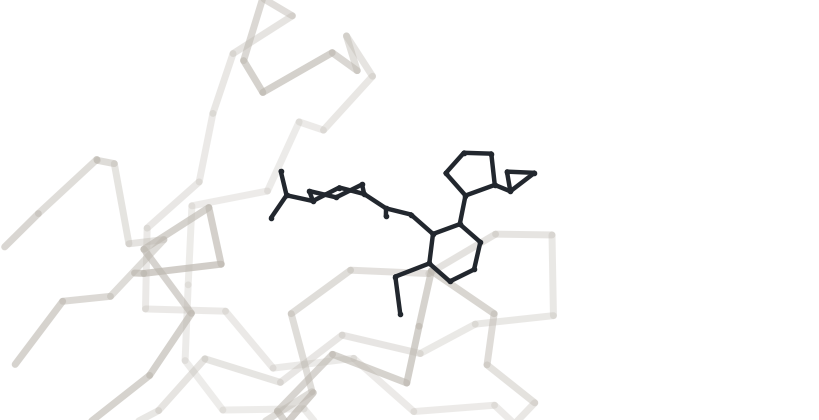

In [45]:
ev71 = wh.load_results("ev71-2a")         # full benchmark results, one row per crystal complex
x7259a = ev71[ev71.complex_name == "A71EV2A-x7259a"].iloc[0]
wh.show_complex(x7259a, models=())

The animation follows 1 compound series from a fragment to a potent follow-on, with each model's prediction
at every step.

![A fragment grown into a potent follow-on](docs/images/campaign.gif)

## 3. Prediction and scoring at scale with Ray Data

⏱ **Budget: 20 minutes.** 3 parts:

1. **3.1 to 3.3** A live pipeline over 8 EV-A71 2A late follow-ons with 3 models, 5 to 10 minutes.
2. **3.4** The same pipeline at scale: all 306 late follow-ons, predicted on 12 L4 GPUs since the start of the session.
3. **3.5** The measurements behind the pipeline settings.

**The 3 models**

| Model | What it is |
|---|---|
| **Boltz-2** | General co-folding model; also predicts binding affinity |
| **OpenBind-0** | OpenFold3 weights released with the OpenBind data (the default checkpoint of OpenFold3 0.5) |
| **OpenFold3 145k** | General OpenFold3 model (`of3-p2-145k`) that predates the OpenBind data. **It is the starting point for the fine-tuning in notebook 02** |

**How Ray Data runs it.** A `Dataset` is a table split into **blocks** in the object store; every step
processes blocks in parallel and streams them onward, so CPU and GPU steps run at the same time.

<img src="docs/images/ray/dataset-arch-with-blocks.svg" alt="Ray Data blocks" width="520">
<img src="docs/images/ray/streaming-topology.svg" alt="Streaming execution" width="520">
<sub>Diagrams: Ray documentation, docs.ray.io (Apache 2.0).</sub>

| Step | Runs on | Does |
|---|---|---|
| `validate` | CPU | Parses each SMILES with RDKit |
| `Boltz2Predictor` | ½ L4 per actor | Pose and affinity with Boltz-2 |
| `OpenBind0` | ½ L4 per actor | Pose with OpenFold3 + OpenBind-0 weights |
| `GeneralOF3` | ½ L4 per actor | Pose with OpenFold3 145k (OpenFold3 0.4.3) |
| `make_scorer` | CPU | Superposes each prediction on its crystal and computes ligand RMSD |

- Model steps are **actors** (`ActorPoolStrategy`): each loads its model once and reuses it for every batch.
- `num_gpus=0.5` puts 2 actors on each L4, so the GPU stays busy while the other actor prepares inputs.

![Pipeline architecture](docs/images/architecture.png)

<img src="docs/images/ray/data-batch-inference.png" alt="Batch inference with Ray Data" width="620">
<sub>Diagram: Ray documentation, docs.ray.io (Apache 2.0).</sub>

### 3.1 Selecting the compounds

x7259a plus 7 other late follow-ons with a curated, non-covalent crystal structure.

In [46]:
# x7259a plus seven other late follow-ons with a curated crystal structure (non-covalent)
lig = ligands["ev71-2a"]
curated = set(ev71.complex_name)
pool = lig[(lig.stage == "late follow-on") & lig.curated_any & ~lig.covalent.astype(bool) & (lig.ligand_id != "x7259a")]
picked = pd.concat([lig[lig.ligand_id == "x7259a"], pool.sample(7, random_state=1)]).reset_index(drop=True)
picked["complexes"] = picked.complexes.map(lambda cs: [c for c in cs if c in curated])
picked[["ligand_id", "smiles", "stage", "experimental_pKD"]]

,ligand_id,smiles,stage,experimental_pKD
0,x7259a,CSc1ncnc(N2CCC[C@@H]2C2CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,7.9380
1,x7025a,CSc1ncnc(N2CC[C@@H](OC(F)F)C2)c1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,6.0481
2,x6934a,CSc1ccccc1[C@@H](NC(=O)C1CC1)C(=O)N1CC[C@H](C(N)=O)C1,late follow-on,4.6120
3,x7096a,CSc1ncnc(N2CCC(C(=O)N(C(C)C)C(C)C)CC2)c1CC(=O)N1CCC[C@H]...,late follow-on,6.2253
4,x6827a,CSc1ccc(C2=CC[NH2+]CC2)cc1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,6.3598
5,x7321a,CC[C@H]1CS[C@H](C(N)=O)CN1C(=O)Oc1cc(Br)ccc1SC,late follow-on,4.1702
6,x7154a,CSc1ncnc(N2CCC(N3CCOC3=O)CC2)c1CC(=O)N1CCC[C@H](C(N)=O)C1,late follow-on,5.9235
7,x7379a,CSc1ccc(-c2cn[nH]c2)cc1OC(=O)N1C[C@@H](C(N)=O)C[C@H]2C[C...,late follow-on,5.6262


### 3.2 Defining the pipeline

Execution is lazy: the cell defines the pipeline; nothing runs until results are requested.

In [47]:
MY_PRED = wh.MINE / "predictions"

class OpenBind0(OF3Predictor):
    # OpenFold3 0.5 with the OpenBind-0 weights, writing to your own folder
    def __init__(self, out_dir):
        super().__init__(key="openbind0", ckpt_path=str(OF3_OB_CKPT), target="ev71-2a", out_dir=out_dir)

class GeneralOF3(OF3Predictor):
    # OpenFold3 145k: its weights load only in OpenFold3 0.4.3, installed alongside at /opt/of3-legacy
    def __init__(self, out_dir):
        super().__init__(key="of3p2", ckpt_path=str(OF3_P2_CKPT), binary=OF3_LEGACY,
                         target="ev71-2a", out_dir=out_dir)

def gpu_step(actors):
    # `actors` model processes, each on half a GPU; each loads its model once and keeps it
    return dict(batch_size=2, batch_format="pandas", num_gpus=0.5, num_cpus=3, accelerator_type=GPU,
                compute=ray.data.ActorPoolStrategy(size=actors, max_tasks_in_flight_per_actor=1))

ds = (ray.data.from_pandas(picked[["ligand_id", "smiles", "complexes", "stage", "experimental_pKD"]])
      .repartition(4)
      .map_batches(validate, batch_format="pandas")                       # CPU
      .map_batches(Boltz2Predictor, **gpu_step(2),                         # GPU: 1 L4
                   fn_constructor_kwargs={"target": "ev71-2a", "out_dir": str(MY_PRED / "boltz2")})
      .map_batches(OpenBind0, **gpu_step(1),                               # GPU: half of a 2nd L4
                   fn_constructor_kwargs={"out_dir": str(MY_PRED / "openbind0")})
      .map_batches(GeneralOF3, **gpu_step(1),                              # GPU: the other half
                   fn_constructor_kwargs={"out_dir": str(MY_PRED / "of3p2")})
      .flat_map(make_scorer(["boltz2", "openbind0", "of3p2"], "ev71-2a")))  # CPU
ds

FlatMap(score)
+- MapBatches(GeneralOF3)
   +- MapBatches(OpenBind0)
      +- MapBatches(Boltz2Predictor)
         +- MapBatches(validate)
            +- Repartition
               +- Dataset(
                     num_rows=8,
                     schema={
                        ligand_id: object,
                        smiles: object,
                        complexes: object,
                        stage: object,
                        experimental_pKD: float64
                     }
                  )

### 3.3 Running the pipeline

⏱ **5–10 minutes on the first run**, mostly GPU nodes starting and models loading. On the Metrics page:
*Node Count* shows nodes joining, *Node GPU* shows them predicting, *Rows output / second* shows each step's progress.

With `USE_GPUS = False` the cell loads the stored predictions for the same 8 compounds instead.

In [48]:
RUN_LIVE = USE_GPUS

t0 = time.time()
mine = ds.to_pandas() if RUN_LIVE else ev71[ev71.ligand_id.isin(picked.ligand_id)].reset_index(drop=True)
print(f"{mine.ligand_id.nunique()} compounds, {len(mine)} crystal complexes scored in {(time.time() - t0) / 60:.1f} min")

models = ["boltz2", "openbind0", "of3p2"]
view = mine[["complex_name"] + [f"{k}_lig_rmsd" for k in models]].copy()
view.columns = ["complex"] + [f"{wh.MODEL_NAMES[k]} RMSD (Å)" for k in models]
(view.style.format(precision=2)
     .map(lambda v: "color:#2E7D4F;font-weight:600" if v < 2 else "color:#B3412E", subset=view.columns[1:]))

8 compounds, 8 crystal complexes scored in 0.0 min


,complex,Boltz-2 RMSD (Å),OpenBind-0 RMSD (Å),OpenFold3 145k (general) RMSD (Å)
0,A71EV2A-x7321a,3.16,0.83,7.08
1,A71EV2A-x6827a,3.08,0.65,5.32
2,A71EV2A-x6934a,2.98,2.42,3.21
3,A71EV2A-x7259a,13.16,0.40,3.65
4,A71EV2A-x7154a,8.93,0.71,7.75
5,A71EV2A-x7025a,6.15,0.37,4.42
6,A71EV2A-x7379a,2.44,0.77,4.69
7,A71EV2A-x7096a,5.31,1.76,5.08


**Interpreting the table.** *Ligand RMSD* is the average distance between each predicted ligand atom and its
crystal counterpart, after superposing the predicted protein on the crystal protein.

- **< 2 Å (green): correct pose.** For scale, a C–C bond is ~1.5 Å.
- **> 2 Å (red):** usually in the pocket but turned the wrong way, which is not useful for design.


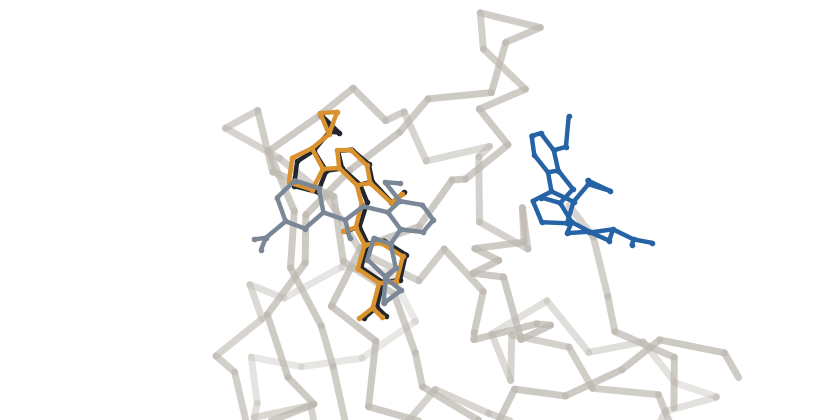

In [49]:
# Your predictions on the crystal: dark = crystal, blue = Boltz-2, amber = OpenBind-0, slate = OpenFold3 145k
wh.show_complex(mine[mine.complex_name == "A71EV2A-x7259a"].iloc[0], models=("boltz2", "openbind0", "of3p2"))

For x7259a:

- **OpenBind-0** reproduces the crystal pose to 0.4 Å.
- **OpenFold3 145k** is in the pocket but 3.7 Å off.
- **Boltz-2** places the compound ~13 Å away, in a different region of the protein.

2 more compounds from this run:


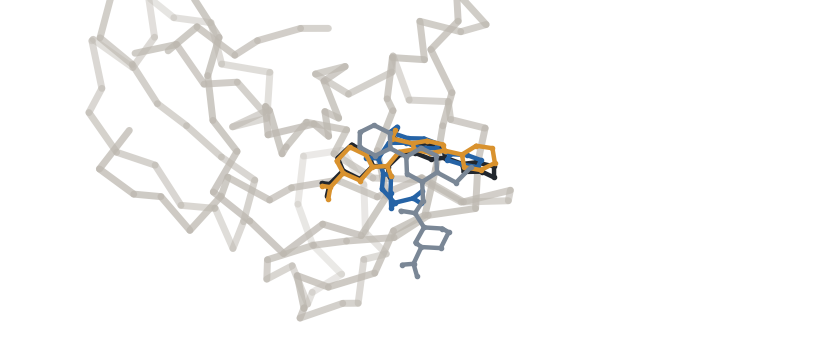


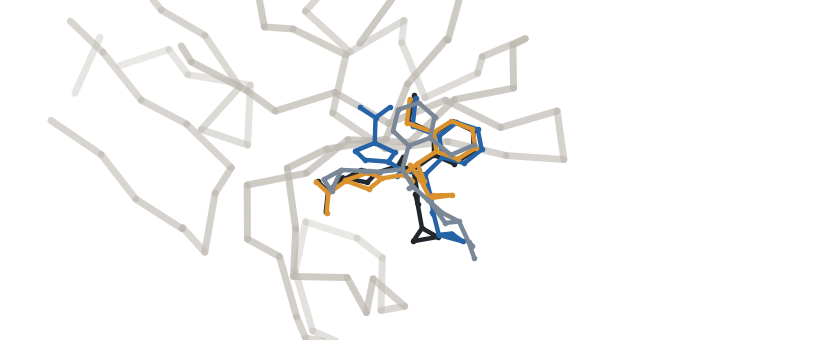

In [50]:
for _, row in mine.drop_duplicates("ligand_id").iloc[1:3].iterrows():
    wh.show_complex(row, models=("boltz2", "openbind0", "of3p2"), height=340)

### 3.4 At scale: all 306 late follow-ons, live

At the start of the session the presenter launched every EV-A71 2A late follow-on through Boltz-2 and
OpenBind-0 on **12 L4 GPUs** (`anyscale job submit -f jobs/workshop.yaml`).

- Each prediction is written to shared storage the moment it finishes.
- The cell below scores whatever is done so far with Ray Data on CPU nodes, and compares it with the full
  benchmark on the same compounds. Run it again to watch the count rise.

In [51]:
# The most recent live run, or set LIVE_RUN_DIR to a specific one
LIVE_RUN_DIR = None
runs = sorted((SHARED / "workshop" / "live").glob("*"))
live_dir = Path(LIVE_RUN_DIR) if LIVE_RUN_DIR else (runs[-1] if runs else None)

late = ligands["ev71-2a"][ligands["ev71-2a"].stage == "late follow-on"].copy()
if live_dir is None:
    print("No live run found. Start one with: anyscale job submit -f jobs/workshop.yaml")
else:
    for k in ("boltz2", "openbind0"):
        cifs = [live_dir / "predictions" / k / f"{l}.cif" for l in late.ligand_id]
        late[f"{k}_cif"] = [str(c) if c.exists() else None for c in cifs]
    done = late.dropna(subset=["boltz2_cif", "openbind0_cif"]).copy()
    print(f"Live run {live_dir.name}: Boltz-2 {late.boltz2_cif.notna().sum()}/{len(late)}, "
          f"OpenBind-0 {late.openbind0_cif.notna().sum()}/{len(late)} compounds predicted")
    done["complexes"] = done.complexes.map(lambda cs: [c for c in cs if c in curated])   # curated crystals only
    done = done[done.complexes.str.len() > 0]
    if len(done):
        live = (ray.data.from_pandas(done[["ligand_id", "complexes", "boltz2_cif", "openbind0_cif"]])
                .repartition(max(1, len(done) // 8))          # eight compounds per CPU task
                .flat_map(make_scorer(["boltz2", "openbind0"], "ev71-2a")).to_pandas())   # CPU tasks
        stored = ev71[ev71.complex_name.isin(live.complex_name)]
        display(pd.DataFrame({f"live run ({len(live)} crystals)": [wh.success(live[f"{k}_lig_rmsd"]) for k in ("boltz2", "openbind0")],
                              "full benchmark, same crystals": [wh.success(stored[f"{k}_lig_rmsd"]) for k in ("boltz2", "openbind0")]},
                             index=["Boltz-2", "OpenBind-0"]).style.format("{:.1f}")
                .set_caption("Share of poses within 2 Å of the crystal structure (%)"))

2026-10-23 12:14:06,584	INFO streaming_executor.py:214 -- Starting execution of Dataset dataset_034l3wHQTlJaHvmlmQlmjS_0. Full logs are in /tmp/ray/session_2026-10-23_10-09-09_819463_3263/logs/ray-data
2026-10-23 12:14:06,585	INFO streaming_executor.py:215 -- Execution plan of Dataset dataset_034l3wHQTlJaHvmlmQlmjS_0: InputDataBuffer[Input] -> AllToAllOperator[Repartition] -> TaskPoolMapOperator[FlatMap(score)]


Live run batch16-20261021-203241: Boltz-2 308/308, OpenBind-0 308/308 compounds predicted


2026-10-23 12:14:06,888	INFO logging_progress.py:174 -- ======= Running Dataset: dataset_034l3wHQTlJaHvmlmQlmjS_0 =======
2026-10-23 12:14:06,889	INFO logging_progress.py:225 -- Total Progress: 0/?
2026-10-23 12:14:06,890	INFO logging_progress.py:227 -- Active & requested resources: 0/0 CPU, 0.0B/0.0B object store
2026-10-23 12:14:06,890	INFO logging_progress.py:181 -- 
2026-10-23 12:14:06,891	INFO logging_progress.py:231 -- Repartition: 0/1
2026-10-23 12:14:06,891	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 1 (158.5KiB); Resources: 0.0 CPU, 0.0B object store; 0 rows output
2026-10-23 12:14:06,892	INFO logging_progress.py:231 --     - Split Repartition: 0/1
2026-10-23 12:14:06,892	INFO logging_progress.py:231 -- FlatMap(score): 0/1
2026-10-23 12:14:06,893	INFO logging_progress.py:233 --   Tasks: 0; Actors: 0; Queued blocks: 0 (0.0B); Resources: 0.0 CPU, 0.0B object store
2026-10-23 12:14:06,893	INFO logging_progress.py:192 -- ==================================

,live run (397 crystals),"full benchmark, same crystals"
Boltz-2,2.3,1.0
OpenBind-0,91.7,91.4


### 3.5 Tuning the pipeline from cluster metrics

The settings used above were derived from the measurements below.

| Observation | Cause | Fix |
|---|---|---|
| 2 OpenFold3 processes per L4 nearly **double** throughput (181 → 327 ligands/hour) | 1 process leaves the GPU idle while it featurizes on CPU | `num_gpus=0.5` |
| OpenFold3 runs **1.44×** faster on a 16-vCPU node than an 8-vCPU node with the same L4 | Featurization is CPU-bound | `g6.4xlarge` for GPU workers |
| A 699-ligand job cycled through **43 nodes** at ~40% GPU utilization | 3 OpenFold3 0.4.3 processes exhausted the 32 GB host RAM; the OS killed Ray on the node | 64 GB nodes, 2 processes per GPU → **402 new predictions in 19 min on 12 L4 at 80% utilization** |

<img src="docs/images/throughput.png" alt="Throughput against predictors per GPU and vCPUs per node" width="820">

GPU utilization per node across a full benchmark: nodes join as work arrives, run at 96% on average, and
are released as each model finishes.

<img src="docs/images/gpu_cluster.png" alt="GPU utilization per node across a run" width="820">

## 4. Results across 3 campaigns

The same pipeline ran on all 3 campaigns before the workshop (1–2 hours per target on 8 L4 GPUs). Results use
the **curated set**: a valid crystal reference and no suspected crystallographic artefact. Every number below
is measured in this pipeline, with 1 predicted pose per compound.

In [52]:
results = {t: wh.load_results(t) for t in wh.TARGET_KEYS}
table = wh.glance(results, models=("boltz2", "openbind0", "of3p2"))
print("Share of poses within 2 Å of the crystal structure (%)")
table.style.format("{:.1f}", na_rep="—").background_gradient(cmap="Greens", vmin=0, vmax=100, axis=None)

Share of poses within 2 Å of the crystal structure (%)


,"EV-A71 2A protease, fragments","EV-A71 2A protease, follow-ons","SARS-CoV-2 Mpro, fragments","SARS-CoV-2 Mpro, follow-ons","MERS-CoV Mpro, follow-ons"
Boltz-2,21.6,3.2,37.5,86.6,86.5
OpenBind-0,28.4,92.7,17.5,89.3,83.3
OpenFold3 145k (general),8.1,36.0,25.0,84.4,69.7


**Observations**

- **Accuracy depends on the target, not just the model.** On SARS-CoV-2 follow-ons, Boltz-2 reaches 87% and
  OpenFold3 145k 84%. On EV-A71 2A the same models reach 3% and 36%.
- **OpenBind-0 is the exception: 93% on EV-A71 2A follow-ons.** Read this number with care:
  - OpenBind-0 comes from the consortium that generated the EV-A71 2A data, and its training cutoff (June 2025)
    is later than almost all of these structures.
  - On SARS-CoV-2 it performs like the general models (89%), and on EV-A71 2A *fragments* it reaches only 28%.
  - Its EV-A71 2A accuracy most likely reflects related training data, so we treat it as an **in-distribution
    reference**, not a test of generalization.
- **Implication for a new project.** A target that appears in no training set starts from the 24% column.
  Notebook 02 measures what target-specific fine-tuning recovers.

In [53]:
wh.by_stage(results["ev71-2a"], models=("boltz2", "openbind0", "of3p2")).style.format("{:.1f}") \
  .set_caption("EV-A71 2A: share of poses within 2 Å by campaign stage (%)")

,fragment,early follow-on,late follow-on
Boltz-2,21.6,5.4,1.0
OpenBind-0,28.4,94.1,91.4
OpenFold3 145k (general),8.1,48.3,23.9


Late follow-ons are the most demanding stage: OpenFold3 145k falls from 48% on early follow-ons to **24%**, and to 13%
on the latest fifth of the campaign.

<img src="docs/images/pose_accuracy.png" alt="Pose accuracy by target and campaign stage" width="860">

Grey is OpenFold3 145k, the general model notebook 02 fine-tunes. Red is the same model after the OpenBind
team fine-tuned it on EV-A71 2A fragments: the before and after of 1 experiment. The fine-tuned model
appears on EV-A71 2A only, the target it was trained for. How it fares on a protease it never saw is a
separate question, answered in notebook 02, Section 5.6.

**Binding affinity.** Boltz-2 also predicts affinity. Spearman ρ measures how well its predictions *rank*
compounds against measured values (1 = identical ranking, 0 = no relationship).

In [54]:
rho = {}
for t, df in results.items():
    a = df.drop_duplicates("ligand_id")[["experimental_pKD", "boltz2_affinity_pred_value"]].astype(float).dropna()
    # Boltz-2 reports log10(IC50 in µM), where lower means tighter binding, so the sign is flipped
    rho[TARGETS[t].name] = {"Spearman": round((-a.boltz2_affinity_pred_value).corr(a.experimental_pKD, "spearman"), 2),
                            "compounds": len(a), "measurement": TARGETS[t].affinity_label}
pd.DataFrame(rho).T

,Spearman,compounds,measurement
EV-A71 2A protease,0.41,482,pKD
SARS-CoV-2 Mpro,0.86,164,pIC50
MERS-CoV Mpro,0.59,142,pIC50


<img src="docs/images/affinity.png" alt="Predicted against measured affinity" width="820">

**Explore.** Enter any complex from the 3 targets, for example `"A71EV2A-x7101a"`, `"MERS-a1994b"` or `"SARS-5rf4-a"`.


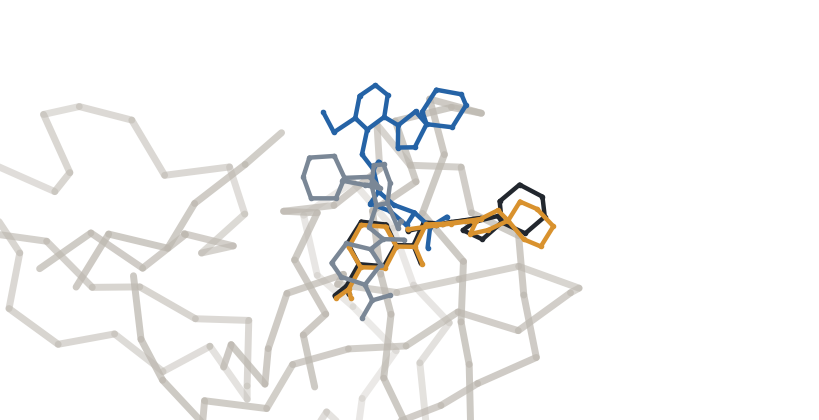

In [55]:
CID = "A71EV2A-x7101a"
row = pd.concat(results.values()).query("complex_name == @CID").iloc[0]
wh.show_complex(row, models=("boltz2", "openbind0", "of3p2"))